# 3. TDR across a search window

Companion to [2. TDR priors](02_tdr_priors.ipynb). Evaluate $D_{90}$ at several possible
GW times, inspect detector availability, reuse strain files, and compare the results.
The example uses three evaluation times.


## 3.1 Why scan a time window?

An uncertain GW–EM delay motivates a search interval around the EM trigger.
Detector availability, noise PSDs and antenna responses can change during that interval,
so $D_{90}(T_0)$ may not represent the full window. FXTs provide one application;
this does not assume that every FXT is a merger.

$D_{90}$ is conditional on the waveform, masses, spins/EOS, inclination prior,
SNR convention and data quality. It is not a model-independent exclusion distance.


## 3.2 Setup

Place this notebook after Samuele's priors notebook in `acme_tutorials/tdr/`.
Reuse its working TDR environment, or install one in a terminal:

```bash
conda create -n gw-tdr python=3.11 pip -y
conda activate gw-tdr
git clone https://github.com/samueleronchini/gw_tdr.git
git clone https://github.com/samueleronchini/acme_tutorials.git
python -m pip install -e ./gw_tdr jupyterlab ipykernel pymupdf tqdm
python -m ipykernel install --user --name gw-tdr --display-name "Python 3.11 (gw_tdr)"
```

Skip clones you already have. TDR also requires `wget` or `curl`.
Launch Jupyter **from the notebook directory** so all generated folders stay alongside it:

```bash
cd acme_tutorials/tdr
OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 jupyter lab
```

Select the TDR kernel. `pymupdf` previews the saved PDF; `tqdm` displays download progress.


In [1]:
# Set thread limits before importing numerical libraries.
import os
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import sys
import importlib.util
import inspect
import json
import hashlib
import math
import shutil
import time
from pathlib import Path

# Check the active environment before requesting data.
required = ("targ_ac_git", "gwosc", "gwpy", "pycbc", "astropy", "pandas", "requests")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if sys.version_info < (3, 11) or missing:
    raise RuntimeError(f"Use the TDR kernel. Python: {sys.executable}; missing: {missing}")

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from astropy.time import Time
from IPython.display import display, Image
from gwosc.timeline import get_segments
from gwosc.locate import get_urls
from targ_ac_git import run_grb
from targ_ac_git.gwosc_utils_snr_mf import _get_run_config
from targ_ac_git.pipeline_utils_snr_mf import _build_offsets, _offset_label
from targ_ac_git.plot_time_evolution import load_rows

needed_arguments = {"grb_name", "t0", "output_dir", "scan_start", "scan_end", "scan_step", "snr_type"}
if needed_arguments - set(inspect.signature(run_grb).parameters):
    raise RuntimeError("Install the current public gw_tdr source in this kernel.")
tools_missing = [name for name in ("pycbc_create_injections", "pycbc_optimal_snr") if not shutil.which(name)]
if tools_missing or not (shutil.which("wget") or shutil.which("curl")):
    raise RuntimeError(f"Check your active environment/PATH; missing PyCBC tools: {tools_missing}; wget/curl is required.")

get_ipython().run_line_magic("matplotlib", "inline")
print("Interpreter:", sys.executable)
print("TDR source:", inspect.getfile(run_grb))
print("Public function:", inspect.signature(run_grb))


/opt/anaconda3/envs/TDR_grb/lib/python3.11/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal
/opt/anaconda3/envs/TDR_grb/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Interpreter: /opt/anaconda3/envs/TDR_grb/bin/python
TDR source: /Users/samueleronchini/Desktop/tdr_time/gw_tdr/targ_ac_git/targ_range_snr_mf.py
Public function: (*, grb_name, t0, output_dir, ra=None, dec=None, skymap_file=None, scan_start=0.0, scan_end=0.0, scan_step=32.0, iota_min=0.0, iota_max=45.0, snr_threshold=9.0, snr_type='mf', cache_dir=None)


## 3.3 Source and analysis settings

Edit the cell below; add new events directly to `SOURCES`. Inclination limits and
SNR threshold are independent of the source type. Offsets are seconds relative to $T_0$.
Changing any input requires rerunning the following cells in order.

The examples are EP240908a ([onset](https://gcn.nasa.gov/circulars/37443),
[position](https://gcn.nasa.gov/circulars/37432)) and GRB200228A.
The $[-1000,+950]$ s window is illustrative; use bounds appropriate to your analysis.
Set `LOCAL_SKYMAP` to an existing local FITS file, or `None` to use RA/Dec only.
No map is downloaded. All output folders are created under the working directory.


In [2]:
# Add events here; coordinates are in degrees and trigger times are UTC.
SOURCES = {
    "EP240908a": dict(name="EP240908a", t0_utc="2024-09-08T17:28:27", ra_deg=14.0031, dec_deg=8.0735),
    "GRB200228A": dict(name="GRB200228A", t0_utc="2020-02-28T06:58:33.806", ra_deg=333.89292, dec_deg=-42.944167),
}

# Edit settings here. No interactive input is required.
SOURCE = "GRB200228A"
LOCAL_SKYMAP = "glg_healpix_all_bn200228291_v00.fit"  # Use None for a fixed RA/Dec.
T_START = -1000.0
T_END = 950.0           # Signed offsets from the EM trigger, in seconds.
SCAN_STEP = 1024.0              # Coarse spacing for the live exercise.
IOTA_MIN_DEG = 0.0
IOTA_MAX_DEG = 90.0
SNR_THRESHOLD = 10.0
SNR_TYPE = "mf"                 # "mf" or "opt".

DOWNLOAD_STRAIN = True
RUN_TDR = True
FORCE_RECOMPUTE = False
BASE_DIR = Path.cwd().resolve()  # Start Jupyter in the notebook directory.

# Validate all user choices before requesting data.
if SOURCE not in SOURCES:
    raise ValueError(f"Add {SOURCE!r} to SOURCES before selecting it.")
event = dict(SOURCES[SOURCE])
if not event["name"] or Path(event["name"]).name != event["name"]:
    raise ValueError("Event name must be a nonempty folder name without a path.")
values = [T_START, T_END, SCAN_STEP, IOTA_MIN_DEG, IOTA_MAX_DEG, SNR_THRESHOLD]
if not all(np.isfinite(value) for value in values):
    raise ValueError("Times, inclination bounds, step and threshold must be finite.")
if T_START > T_END:
    raise ValueError("Require T_START <= T_END.")
if SCAN_STEP <= 0:
    raise ValueError("SCAN_STEP must be positive.")
if SNR_THRESHOLD <= 0:
    raise ValueError("SNR_THRESHOLD must be positive.")
if not 0 <= IOTA_MIN_DEG < IOTA_MAX_DEG <= 90:
    raise ValueError("Require 0 <= iota_min < iota_max <= 90 degrees.")
if SNR_TYPE not in ("mf", "opt"):
    raise ValueError("SNR_TYPE must be 'mf' or 'opt'.")

# Validate the local map and any supplied coordinates; never query an online map.
USE_SKYMAP = LOCAL_SKYMAP is not None
if USE_SKYMAP:
    LOCAL_SKYMAP = Path(LOCAL_SKYMAP).expanduser().resolve()
    if not LOCAL_SKYMAP.is_file():
        raise FileNotFoundError(f"Localization map not found: {LOCAL_SKYMAP}")
ra, dec = event["ra_deg"], event["dec_deg"]
if not USE_SKYMAP and (ra is None or dec is None):
    raise ValueError("Supply RA and Dec, or provide a localization map.")
if ra is not None and not (np.isfinite(ra) and 0 <= ra < 360):
    raise ValueError("RA must be finite and in [0, 360) degrees.")
if dec is not None and not (np.isfinite(dec) and -90 <= dec <= 90):
    raise ValueError("Dec must be finite and in [-90, 90] degrees.")

# GPS is used internally; the next cell displays UTC times.
try:
    T0 = float(Time(event["t0_utc"], format="isot", scale="utc").gps)
except (TypeError, ValueError) as exc:
    raise ValueError("Use a valid UTC time: YYYY-MM-DDTHH:MM:SS.sss") from exc
WINDOW_START, WINDOW_END = T0 + T_START, T0 + T_END
QUERY_START = math.floor(WINDOW_START - 128)  # Half of the 256 s PSD segment.
QUERY_STOP = math.ceil(WINDOW_END + 128)
run_config = _get_run_config(T0)
IFOS = tuple(run_config["ifos"])
for query_time in (QUERY_START, QUERY_STOP):
    if _get_run_config(query_time)["name"] != run_config["name"]:
        raise ValueError("Choose a window contained in one observing run.")

print("Settings validated:", event["name"])
print(f"Inclination: {IOTA_MIN_DEG:g}–{IOTA_MAX_DEG:g} deg")
print(f"SNR type: {SNR_TYPE}; threshold: {SNR_THRESHOLD:g}")
print("Base directory:", BASE_DIR)


Settings validated: GRB200228A
Inclination: 0–90 deg
SNR type: mf; threshold: 10
Base directory: /Users/samueleronchini/Desktop/acme_tutorials/tdr


In [3]:
# Keep strain and metadata together under the selected event folder.
EVENT_DIR = BASE_DIR / event["name"]
CACHE_DIR, META_DIR = EVENT_DIR / "gwosc_cache", EVENT_DIR / "metadata"
META_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
META_FILE = META_DIR / f"gwosc_{QUERY_START}_{QUERY_STOP}.json"

display(pd.DataFrame({
    "Quantity": ["EM reference", "Search start", "Search end", "Strain envelope start", "Strain envelope end"],
    "UTC": [Time(t, format="gps").utc.isot for t in (T0, WINDOW_START, WINDOW_END, QUERY_START, QUERY_STOP)],
}))
print("Observing run:", run_config["name"])
print("Configured detectors:", ", ".join(IFOS))
print("Output folder:", EVENT_DIR)
print("Strain cache:", CACHE_DIR)


,Quantity,UTC
0,EM reference,2020-02-28T06:58:33.806
1,Search start,2020-02-28T06:41:53.806
2,Search end,2020-02-28T07:14:23.806
3,Strain envelope start,2020-02-28T06:39:45.000
4,Strain envelope end,2020-02-28T07:16:32.000


Observing run: O3b
Configured detectors: H1, L1, V1
Output folder: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A
Strain cache: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache


## 3.4 Detector availability

Query and cache the public GWOSC DATA intervals, then plot them across the search window.
These flags describe released usable data, not every engineering observing transition.
The query includes 128 s on either side for PSD estimation; TDR later checks the full
strain segment and PSD. A failed query means unknown availability, not an offline detector.


Metadata retrieved (UTC): 2026-10-21T13:48:11.996


,IFO,DATA intervals (GPS)
0,H1,"[[1266907203, 1266909410]]"
1,L1,"[[1266907203, 1266909410]]"
2,V1,"[[1266907203, 1266909410]]"


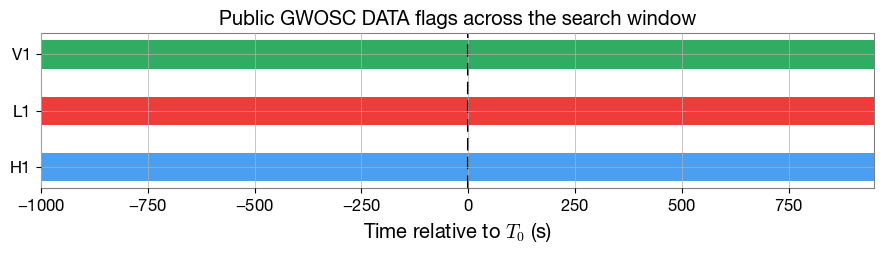

In [4]:
# Reuse metadata only when its query interval matches the current settings.
if META_FILE.exists():
    metadata = json.loads(META_FILE.read_text())
else:
    metadata = {"query_start": QUERY_START, "query_stop": QUERY_STOP,
                "retrieved_utc": Time.now().utc.isot, "segments": {}, "urls": {}}
if (metadata["query_start"], metadata["query_stop"]) != (QUERY_START, QUERY_STOP):
    raise RuntimeError("Metadata cache belongs to a different time interval.")
for ifo in IFOS:
    if ifo not in metadata["segments"]:
        try:
            metadata["segments"][ifo] = get_segments(f"{ifo}_DATA", QUERY_START, QUERY_STOP)
        except Exception as exc:
            raise RuntimeError(f"Could not query {ifo}_DATA; availability is unknown, not offline.") from exc
META_FILE.write_text(json.dumps(metadata, indent=2))
segments = metadata["segments"]
print("Metadata retrieved (UTC):", metadata["retrieved_utc"])
display(pd.DataFrame([{"IFO": ifo, "DATA intervals (GPS)": segments[ifo]} for ifo in IFOS]))

# Clip each DATA interval to the requested window and plot offsets from T0.
ifo_colors = {"H1": "#4C9FEF", "L1": "#F03B3B", "V1": "#30AD63"}
fig, ax = plt.subplots(figsize=(9, 2.7))
for row, ifo in enumerate(IFOS):
    for start, stop in segments[ifo]:
        left, right = max(start, WINDOW_START), min(stop, WINDOW_END)
        if right > left:
            ax.broken_barh([(left - T0, right - left)], (row - .25, .5), facecolors=ifo_colors[ifo])
ax.axvline(0, color="black", linestyle=(0, (6, 3)), label=r"$T_0$")
plot_left, plot_right = (T_START, T_END) if T_START < T_END else (T_START - .5, T_END + .5)
ax.set(xlim=(plot_left, plot_right), yticks=range(len(IFOS)), yticklabels=IFOS,
       xlabel=r"Time relative to $T_0$ (s)", title="Public GWOSC DATA flags across the search window")
fig.tight_layout()
display(fig)
plt.close(fig)


## 3.5 Evaluation times

The grid uses multiples of `SCAN_STEP` anchored at $T_0$, plus the exact `T_START`
and `T_END`. It sorts and removes duplicates; endpoints are never rounded.
Zero is included when it falls inside the window.

For example, $[-100,70.5]$ s with a 32 s step gives
`[-100, -96, -64, -32, 0, 32, 64, 70.5]`.
The current $[-1000,950]$ s window with a 1024 s step gives three centers.
These are evaluation times, not disjoint strain segments.


In [5]:
# Use the production grid so exact endpoints and the T0 anchor are preserved.
offsets = _build_offsets(scan_start=T_START, scan_end=T_END, scan_step=SCAN_STEP)
centers = T0 + np.asarray(offsets)
scan_table = pd.DataFrame({
    "offset_s": offsets,
    "GW_time_UTC": Time(centers, format="gps").utc.isot,
    "folder": [_offset_label(offset) for offset in offsets],
})
print(f"Number of evaluation times: {len(offsets)}")
print("Offsets (s):", offsets)
print("Actual consecutive spacings (s):", np.diff(offsets).tolist())
assert offsets[0] == T_START and offsets[-1] == T_END
assert all(T_START <= offset <= T_END for offset in offsets)
display(scan_table)


Number of evaluation times: 3
Offsets (s): [-1000.0, 0.0, 950.0]
Actual consecutive spacings (s): [1000.0, 950.0]


,offset_s,GW_time_UTC,folder
0,-1000.0,2020-02-28T06:41:53.806,scan_t0m1000
1,0.0,2020-02-28T06:58:33.806,scan_t0p0000
2,950.0,2020-02-28T07:14:23.806,scan_t0p0950


In [6]:
# True means the DATA flag is active at that center; full-segment checks come later.
availability_rows = []
for offset, center in zip(offsets, centers):
    row = {"Offset (s)": offset}
    for ifo in IFOS:
        row[ifo] = any(start <= center < stop for start, stop in segments[ifo])
    availability_rows.append(row)
availability_table = pd.DataFrame(availability_rows)
display(availability_table.style.hide(axis="index"))


Offset (s),H1,L1,V1
-1000.000000,True,True,True
0.000000,True,True,True
950.000000,True,True,True


## 3.6 Strain downloads

List the unique files covering the search window and its PSD padding, then download
missing files with `tqdm` progress bars. Each center reads its own 256 s segment from
this shared cache. Multiple centers can reuse one file; prefetch computes no PSD or $D_{90}$.


In [7]:
# Cache file URLs and list each file once per detector.
download_rows = []
for ifo in IFOS:
    if ifo not in metadata["urls"]:
        metadata["urls"][ifo] = get_urls(ifo, QUERY_START, QUERY_STOP, sample_rate=4096, format="hdf5")
    for url in dict.fromkeys(metadata["urls"][ifo]):
        name = url.rsplit("/", 1)[-1]
        download_rows.append({"IFO": ifo, "file": name, "already_cached": (CACHE_DIR / name).is_file(), "url": url})
META_FILE.write_text(json.dumps(metadata, indent=2))
download_plan = pd.DataFrame(download_rows, columns=["IFO", "file", "already_cached", "url"])
display(download_plan.drop(columns="url"))
print("Unique strain files:", len(download_plan), "| evaluation centers:", len(offsets))
print("Shared strain cache:", CACHE_DIR)


,IFO,file,already_cached
0,H1,H-H1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5,True
1,H1,H-H1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5,True
2,L1,L-L1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5,True
3,L1,L-L1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5,False
4,V1,V-V1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5,False
5,V1,V-V1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5,False


Unique strain files: 6 | evaluation centers: 3
Shared strain cache: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache


In [8]:
from urllib.parse import urlparse
from tqdm import tqdm

def prefetch_with_progress(url, cache_dir):
    """Skip cached files; promote a .part download only after it completes."""
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    destination = cache_dir / Path(urlparse(url).path).name
    partial_file = destination.with_name(destination.name + ".part")
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already cached: {destination.name}")
        return destination

    with requests.get(url, stream=True, timeout=35, headers={"Accept-Encoding": "identity"}) as response:
        response.raise_for_status()
        total = int(response.headers.get("Content-Length", 0)) or None
        with (
            partial_file.open("wb") as output,
            tqdm(total=total, desc=destination.name, unit="B", unit_scale=True,
                 unit_divisor=1024, dynamic_ncols=True, leave=True) as progress,
        ):
            for chunk in response.iter_content(chunk_size=64 * 1024):
                if chunk:
                    output.write(chunk)
                    progress.update(len(chunk))

    # Never rename a known incomplete transfer as a finished cache file.
    if total is not None and partial_file.stat().st_size != total:
        raise IOError(f"Incomplete download: {destination.name}")
    partial_file.replace(destination)
    return destination

if DOWNLOAD_STRAIN:
    for row in download_rows:
        prefetch_with_progress(row["url"], CACHE_DIR)
    print("Strain prefetch complete. No D90 calculations have run yet.")
else:
    print("Prefetch skipped. Use this setting only with prepared completed results, or an already populated cache.")


Already cached: H-H1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5
Already cached: H-H1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5
Already cached: L-L1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5


L-L1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5: 100%|██████████| 123M/123M [03:14<00:00, 665kB/s]  
V-V1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5: 100%|██████████| 124M/124M [03:05<00:00, 701kB/s]  
V-V1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5: 100%|██████████| 77.8M/77.8M [01:55<00:00, 705kB/s] 

Strain prefetch complete. No D90 calculations have run yet.


### Results directory

Use the validated local map, if supplied. A hash of the analysis settings and map content
identifies the results folder, keeping different configurations separate.


In [9]:
# Include map content in the run ID so replacing the FITS file changes the results folder.
skymap_file = LOCAL_SKYMAP if USE_SKYMAP else None
settings = dict(
    event=event["name"], t0_gps=T0, ra_deg=event["ra_deg"], dec_deg=event["dec_deg"],
    scan_start=T_START, scan_end=T_END, scan_step=SCAN_STEP,
    iota_min=IOTA_MIN_DEG, iota_max=IOTA_MAX_DEG, snr_threshold=SNR_THRESHOLD, snr_type=SNR_TYPE,
    skymap_sha256=hashlib.sha256(skymap_file.read_bytes()).hexdigest() if skymap_file is not None else None,
)
run_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:12]
OUTPUT_DIR = EVENT_DIR / "time_evolution" / run_id
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Results directory:", OUTPUT_DIR)


Results directory: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/time_evolution/3d7b0530bbe5


## 3.7 Run the scan

`run_grb()` repeats the single-time calculation at each center, checking strain and PSDs
and saving separate results. The outer loop does not change the waveform or $D_{90}$ algorithm.
Matching completed results are reused unless `FORCE_RECOMPUTE=True`.
For the live exercise, predownload the strain; a finer scan can be run afterward.


In [10]:
# Reuse only matching results with the requested centers and no failed bins.
summary_file = OUTPUT_DIR / "scan_summary.json"
settings_file = OUTPUT_DIR / "tutorial_settings.json"
can_reuse = summary_file.exists() and settings_file.exists() and not FORCE_RECOMPUTE
if can_reuse:
    if json.loads(settings_file.read_text()) != settings:
        raise RuntimeError("Existing results have different settings.")
    summary = json.loads(summary_file.read_text())
    if [item["offset_s"] for item in summary["bins"]] != offsets or any(item["status"] == "failed" for item in summary["bins"]):
        raise RuntimeError("Existing scan is incomplete/failed; inspect its log before recomputing.")
    print("Reusing the matching completed scan:", OUTPUT_DIR)
elif RUN_TDR:
    settings_file.write_text(json.dumps(settings, indent=2))
    started = time.monotonic()
    summary = run_grb(
        grb_name=event["name"], t0=event["t0_utc"], output_dir=OUTPUT_DIR,
        ra=event["ra_deg"], dec=event["dec_deg"], skymap_file=skymap_file,
        scan_start=T_START, scan_end=T_END, scan_step=SCAN_STEP,
        iota_min=IOTA_MIN_DEG, iota_max=IOTA_MAX_DEG,
        snr_threshold=SNR_THRESHOLD, snr_type=SNR_TYPE, cache_dir=CACHE_DIR,
    )
    print(f"Scan finished in {(time.monotonic()-started)/60:.1f} min")
else:
    raise FileNotFoundError("No matching completed scan. Set RUN_TDR=True or restore the instructor's matching prepared run.")

# These are the detectors accepted by TDR after the strain and PSD checks.
display(pd.DataFrame([
    {"offset_s": item["offset_s"], "folder": item["scan_name"], "status": item["status"],
     "IFOs actually used": ",".join(item.get("online_ifos") or []) or "none"}
    for item in summary["bins"]
]))


EVENT RUN = O3b
USING GWOSC STRAIN SAMPLE RATE: 4096 Hz
USING SNR TYPE: matched_filter
USING SNR THRESHOLD: 10
USING INCLINATION PRIOR(S):
  0.0 deg <= iota <= 90.0 deg
USING GWOSC CACHE DIR: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache
RUNNING 3 SCAN BIN(S): [-1000.0, 0.0, 950.0]
[scan_t0m1000] START at t=1266907331.806
Data H-H1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5 already present in cache. Skipping download.
Data L-L1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5 already present in cache. Skipping download.
Data V-V1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5 already present in cache. Skipping download.
IFOs with available strain data: H1,L1,V1
IFOs used in the analysis:      H1,L1,V1


setting the output map dtype to [dtype('float64')]
INFO:targ_range:scan_t0m1000: finished compute_range
INFO:targ_range:scan_t0m1000: starting plot_final
INFO:targ_range:scan_t0m1000: finished plot_final
INFO:targ_range:scan_t0m1000: completed analysis


[scan_t0m1000] DONE in 37.32 s (0.62 min)
[scan_t0p0000] START at t=1266908331.806


INFO:targ_range:scan_t0p0000: loading GWOSC strain with 3 worker(s)


Data H-H1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5 already present in cache. Skipping download.


...

INFO:targ_range:scan_t0p0950: run=O3b ifo=V1 channel=V1:Hrec_hoft_16384Hz frame_type=V1Online sample_rate=4096 strain usable from ['/Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache/V-V1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5', '/Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache/V-V1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5']
INFO:targ_range:scan_t0p0950: run=O3b ifo=L1 channel=L1:DCS-CALIB_STRAIN_CLEAN_SUB60HZ_C01 frame_type=L1_HOFT_CLEAN_SUB60HZ_C01 sample_rate=4096 strain usable from ['/Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache/L-L1_GWOSC_O3b_4KHZ_R1-1266905088-4096.hdf5', '/Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/gwosc_cache/L-L1_GWOSC_O3b_4KHZ_R1-1266909184-4096.hdf5']
INFO:targ_range:scan_t0p0950: run=O3b ifo=H1 channel=H1:DCS-CALIB_STRAIN_CLEAN_SUB60HZ_C01 frame_type=H1_HOFT_CLEAN_SUB60HZ_C01 sample_rate=4096 strain usable from ['/Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB20022

IFOs with available strain data: H1,L1,V1
IFOs used in the analysis:      H1,L1,V1


INFO:targ_range:IFOs with available strain data: H1,L1,V1 | IFOs used in the analysis:      H1,L1,V1
INFO:targ_range:scan_t0p0950: final usable IFOs = ['H1', 'L1', 'V1']
INFO:targ_range:scan_t0p0950: IFO status = {'H1': {'strain_available': True, 'psd_ok': True, 'usable': True, 'network_failed': False, 'reason': 'strain complete and PSD valid'}, 'L1': {'strain_available': True, 'psd_ok': True, 'usable': True, 'network_failed': False, 'reason': 'strain complete and PSD valid'}, 'V1': {'strain_available': True, 'psd_ok': True, 'usable': True, 'network_failed': False, 'reason': 'strain complete and PSD valid'}}
INFO:targ_range:scan_t0p0950: starting plot_psd
INFO:targ_range:scan_t0p0950: finished plot_psd
INFO:targ_range:scan_t0p0950: starting injections and pycbc_optimal_snr
INFO:targ_range:scan_t0p0950: starting pycbc_optimal_snr for bns m1=1 m2=1
INFO:targ_range:scan_t0p0950: finished pycbc_optimal_snr for bns m1=1 m2=1 in 1.93 s
INFO:targ_range:scan_t0p0950: starting pycbc_optimal_snr

[scan_t0p0950] DONE in 34.82 s (0.58 min)
ANALYSIS COMPLETE in 107.29 s (1.79 min)
Scan finished in 1.8 min


,offset_s,folder,status,IFOs actually used
0,-1000.0,scan_t0m1000,complete,"H1,L1,V1"
1,0.0,scan_t0p0000,complete,"H1,L1,V1"
2,950.0,scan_t0p0950,complete,"H1,L1,V1"


## 3.8 Output folders

Folders encode the time offset:

| Folder | Candidate GW time |
|---|---|
| `scan_t0m1000/` | $T_0-1000$ s |
| `scan_t0p0000/` | $T_0$ |
| `scan_t0p0950/` | $T_0+950$ s |

Each completed folder contains detector-status information, PSDs, injections, SNR results,
BNS/NSBH JSON files and plots. `scan_summary.json` lists the bins; `gwosc_cache/` is shared.
JSON results include the selected and $0$–$90^\circ$ priors, with one entry if identical.
A center with no usable detector has missing $D_{90}$, not $D_{90}=0$.


## 3.9 Results and time-evolution plot

The table reads **all stored mass configurations** for the selected inclination prior.
The saved PDF shows BNS $(1.4,1.4)\,M_\odot$ and NSBH $(10,1.4)\,M_\odot$;
the NSBH values follow the code's EOS averaging.

Colors show the network antenna magnitude at a fixed source position, or its **area mean
within the map's 90% credible region**. This color statistic does not replace the
probability-weighted sky samples used for $D_{90}$.
The lower panel displays detectors used at sampled times; use the earlier DATA timeline
for actual flag boundaries.


In [11]:
# Read every mass configuration for the selected prior, keeping antenna factor after network.
rows = load_rows(str(OUTPUT_DIR), summary)
table_rows = []
mass_columns = {"bns": [], "nsbh": []}
for row in rows:
    table_row = {
        "Offset (s)": row["offset_s"], "Status": row["status"],
        "Network": ",".join(row.get("online_ifos") or []) or "none",
        "Antenna factor": (row.get("antenna_factor") or {}).get("network", np.nan),
    }
    if row["status"] == "complete":
        bin_dir = OUTPUT_DIR / row["scan_name"]
        for family in ("bns", "nsbh"):
            results_file = bin_dir / f"results_{family}.json"
            results = json.loads(results_file.read_text())[family]
            for mass_label, entry in results.items():
                masses = mass_label.replace("m1=", "").replace("m2=", "")
                column = f"{family.upper()} ({masses}) D90 (Mpc)"
                if column not in mass_columns[family]:
                    mass_columns[family].append(column)
                value = entry["tdr"][summary["user_prior"]]["D90_Mpc"]
                table_row[column] = np.nan if value is None else float(value)
    table_rows.append(table_row)

columns = ["Offset (s)", "Status", "Network", "Antenna factor", *mass_columns["bns"], *mass_columns["nsbh"]]
evolution = pd.DataFrame(table_rows).reindex(columns=columns)
display(evolution.style.hide(axis="index").format(precision=3, na_rep="—"))

# Preview the saved production PDF; this does not rerun TDR.
pdf_path = OUTPUT_DIR / f"{event['name']}_D90_and_IFO_windows_combined.pdf"
try:
    import fitz
except ImportError:
    print("Open the saved PDF:", pdf_path)
    print("For an inline preview: install pymupdf in this kernel and rerun this cell.")
else:
    with fitz.open(pdf_path) as document:
        display(Image(data=document[0].get_pixmap(matrix=fitz.Matrix(1.4, 1.4), alpha=False).tobytes("png")))
print("Saved production plot:", pdf_path)


Offset (s),Status,Network,Antenna factor,"BNS (1, 1) D90 (Mpc)","BNS (1.4, 1.4) D90 (Mpc)","BNS (2.0, 2.0) D90 (Mpc)","NSBH (5, 1) D90 (Mpc)","NSBH (10, 1.4) D90 (Mpc)","NSBH (20, 2.0) D90 (Mpc)"
-1000.000,complete,"H1,L1,V1",1.394,68.400,89.073,119.200,114.132,171.207,265.953
0.000,complete,"H1,L1,V1",1.378,68.633,89.835,120.836,116.589,173.554,268.219
950.000,complete,"H1,L1,V1",1.361,66.788,88.770,118.189,113.744,170.042,263.249


Open the saved PDF: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/time_evolution/3d7b0530bbe5/GRB200228A_D90_and_IFO_windows_combined.pdf
For an inline preview: install pymupdf in this kernel and rerun this cell.
Saved production plot: /Users/samueleronchini/Desktop/acme_tutorials/tdr/GRB200228A/time_evolution/3d7b0530bbe5/GRB200228A_D90_and_IFO_windows_combined.pdf


### Compare one time with the sampled range

Choose an evaluated `REFERENCE_OFFSET` below. The table compares its $D_{90}$ with
the sampled minimum and maximum for every mass pair; it does not evaluate a new time.
These extrema describe the sampled centers, not a continuously measured curve.


In [12]:
REFERENCE_OFFSET = -1000.0  # Choose an evaluated offset, e.g. -1000, 0 or 950 s.
selected = evolution.loc[np.isclose(evolution["Offset (s)"], REFERENCE_OFFSET, rtol=0, atol=1e-6)]
if selected.empty:
    available = evolution["Offset (s)"].tolist()
    raise ValueError(f"Offset {REFERENCE_OFFSET:g} s was not evaluated. Choose from: {available}")

# Ignore missing distances when calculating sampled extrema.
comparison = []
for column in mass_columns["bns"] + mass_columns["nsbh"]:
    values = evolution[column].dropna()
    comparison.append({
        "System": column.removesuffix(" D90 (Mpc)"),
        f"D90 at {REFERENCE_OFFSET:g} s (Mpc)": selected.iloc[0][column],
        "Sampled min (Mpc)": values.min(), "Sampled max (Mpc)": values.max(),
        "Valid centers / requested": f"{len(values)}/{len(offsets)}",
    })
display(pd.DataFrame(comparison).style.hide(axis="index").format(precision=3, na_rep="—"))


System,D90 at -1000 s (Mpc),Sampled min (Mpc),Sampled max (Mpc),Valid centers / requested
"BNS (1, 1)",68.400,66.788,68.633,3/3
"BNS (1.4, 1.4)",89.073,88.770,89.835,3/3
"BNS (2.0, 2.0)",119.200,118.189,120.836,3/3
"NSBH (5, 1)",114.132,113.744,116.589,3/3
"NSBH (10, 1.4)",171.207,170.042,173.554,3/3
"NSBH (20, 2.0)",265.953,263.249,268.219,3/3


## 3.10 Optional: compare detector noise

Choose `PSD_IFO` and overlay its saved amplitude spectral densities at the evaluated times.
Missing PSD files are skipped. Explicit dash patterns distinguish the curves in the legend.


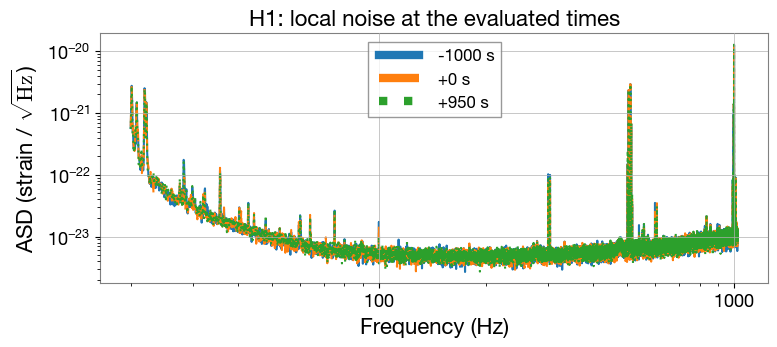

In [13]:
PSD_IFO = "H1"  # Choose H1, L1 or V1.
fig, ax = plt.subplots(figsize=(8, 3.7))
styles = ["solid", (0, (6, 3)), (0, (1, 2))]
for index, item in enumerate(summary["bins"]):
    path = OUTPUT_DIR / item["scan_name"] / f"{PSD_IFO.lower()}_psd.txt"
    if path.exists():
        frequency, psd = np.loadtxt(path).T
        keep = (frequency >= 20) & (frequency <= 1024)
        ax.loglog(frequency[keep], np.sqrt(psd[keep]), linestyle=styles[index % len(styles)],
                  label=f"{item['offset_s']:+g} s", linewidth=1.5)
ax.set(xlabel="Frequency (Hz)", ylabel=r"ASD (strain / $\sqrt{\rm Hz}$)",
       title=f"{PSD_IFO}: local noise at the evaluated times")
if ax.lines:
    ax.legend(handlelength=3)
else:
    ax.text(.5, .5, "No PSD files for this detector", transform=ax.transAxes, ha="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "tutorial_psd_comparison.png", dpi=140)
display(fig)
plt.close(fig)


### Interpreting an unknown-delay window

Changes in $D_{90}$ can reflect detector availability, PSDs, antenna response and Monte Carlo
sampling. A single exclusion distance for an unknown merger time also requires a delay prior:
average the efficiencies, $\bar\epsilon(D)=\int\epsilon(D,t)p(t)\,dt$, including detector gaps,
then find the 90% crossing. Do not simply average $D_{90}(t)$.

References: [TDR code](https://github.com/samueleronchini/gw_tdr),
[GWOSC DATA definition](https://gwosc.org/datadef/),
[timeline client](https://gwosc.readthedocs.io/en/stable/timeline.html),
[O4b release](https://gwosc.org/O4/O4b/).
